# Spam Detection using NLP and Machine Learning — Oasis Infobyte Task 4

## 1. Introduction

### Project Objective
The objective of this project is to develop an automated Natural Language Processing (NLP) and Machine Learning classification system capable of accurately classifying incoming SMS messages and emails as either **Ham** (legitimate) or **Spam** (unsolicited / fraudulent).

### Why NLP is Useful
Unstructured human language cannot be directly interpreted by mathematical algorithms. NLP provides standard text normalization pipelines (lowercasing, punctuation stripping, stopword filtering) and vectorization techniques (such as **TF-IDF**) that transform raw conversational strings into meaningful numerical feature matrices while retaining important term frequency statistics.

### Problem Formulation
This is a **binary text classification** problem:
- **Target**: `label`
  - `ham`: Legitimate personal or business communications ($0$)
  - `spam`: Unsolicited advertisements, phishing links, and promotional messages ($1$)

## 2. Import Libraries
Import required libraries for numerical computing, data analysis, visualization, NLP, and machine learning.

In [12]:
# Challenge 1: Import required libraries (numpy, pandas, matplotlib, seaborn, re, string, nltk, sklearn)
# Core data & numerical libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Text processing libraries
import re
import string
import nltk
from nltk.corpus import stopwords

# Scikit-learn NLP & modeling tools
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

# Styling
sns.set_theme(style="whitegrid")
%matplotlib inline

print("All NLP and Machine Learning libraries imported successfully!")

All NLP and Machine Learning libraries imported successfully!


## 3. Load Dataset
Load the classic SMS Spam Collection dataset (`spam.csv`).

In [13]:
# Challenge 2: Load spam.csv and display first 5 rows
# Load the dataset
df = pd.read_csv("spam.csv")

# Display dimensions and the first 5 records
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 4. Data Inspection
Inspect dataset dimensions, missing values, duplicates, and message length characteristics.

In [14]:
# Challenge 3: Check shape, info, nulls, duplicates, and message lengths
# 1. Inspect data types and missing values
print("--- Missing Values ---")
print(df.isnull().sum())

# 2. Check for duplicate messages
duplicate_count = df.duplicated().sum()
print(f"\nDuplicate messages: {duplicate_count}")

# 3. Remove duplicates to ensure clean evaluation
df = df.drop_duplicates().reset_index(drop=True)
print(f"Cleaned dataset shape: {df.shape}")

# 4. Feature engineering: Add message length
df['length'] = df['message'].apply(len)
df.head()

--- Missing Values ---
label      0
message    0
dtype: int64

Duplicate messages: 403
Cleaned dataset shape: (5169, 2)


,label,message,length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


## 5. Class Distribution
Analyze class proportions (Spam vs. Ham) in counts and percentages, and visualize class imbalance.

--- Class Distribution ---
       Count  Percentage (%)
label                       
ham     4516           87.37
spam     653           12.63


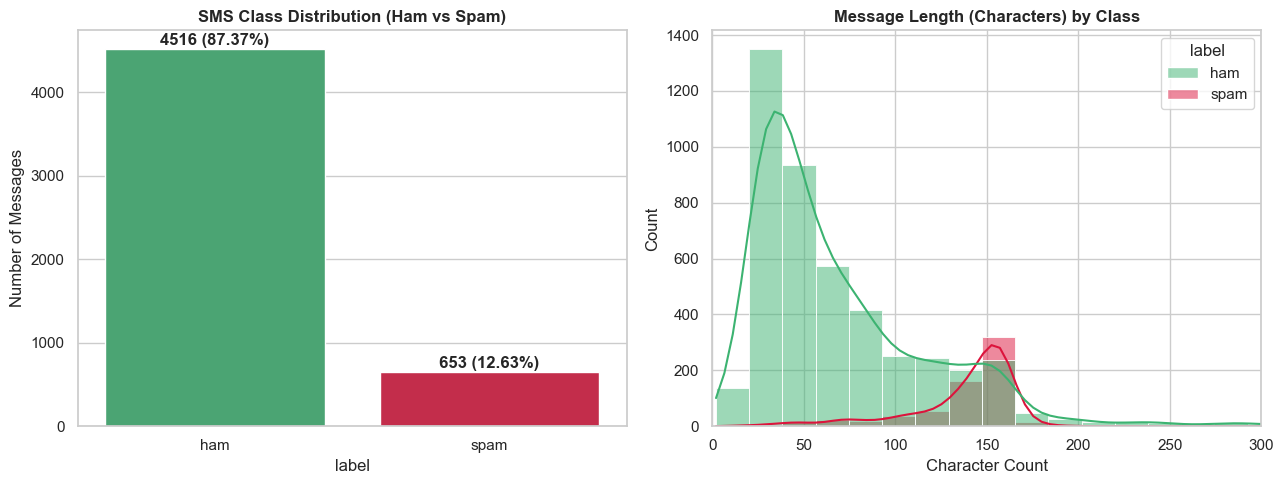

In [15]:
# Challenge 4: Compute exact counts and percentages of Ham vs Spam, and plot distribution
# 1. Compute exact counts and percentages
counts = df['label'].value_counts()
percentages = (df['label'].value_counts(normalize=True) * 100).round(2)

dist_df = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': percentages
})
print("--- Class Distribution ---")
print(dist_df)

# 2. Visualise class distribution & message length distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Class Count Bar Chart
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, legend=False, palette=['mediumseagreen', 'crimson'], ax=axes[0])
axes[0].set_title("SMS Class Distribution (Ham vs Spam)", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Number of Messages")
for i, count in enumerate(counts.values):
    axes[0].text(i, count + 50, f"{count} ({percentages.iloc[i]}%)", ha='center', fontweight='bold')

# Plot 2: Message Length by Class
sns.histplot(data=df, x='length', hue='label', bins=50, palette=['mediumseagreen', 'crimson'], ax=axes[1], kde=True)
axes[1].set_title("Message Length (Characters) by Class", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Character Count")
axes[1].set_xlim(0, 300)

plt.tight_layout()
plt.show()

## 6. Text Preprocessing
Construct a clean, modular NLP text preprocessing pipeline:
1. **Lowercase Conversion**: Standardize all characters to avoid case discrepancy.
2. **Punctuation Removal**: Strip non-alphanumeric punctuation marks.
3. **Stopword Removal**: Remove ubiquitous English words (e.g. 'the', 'is', 'at') that carry zero discriminative signal.

--- Preprocessing Example ---
Raw message:      Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Cleaned message:  free entry 2 wkly comp win fa cup final tkts 21st may 2005 text fa 87121 receive entry questionstd txt ratetcs apply 08452810075over18s


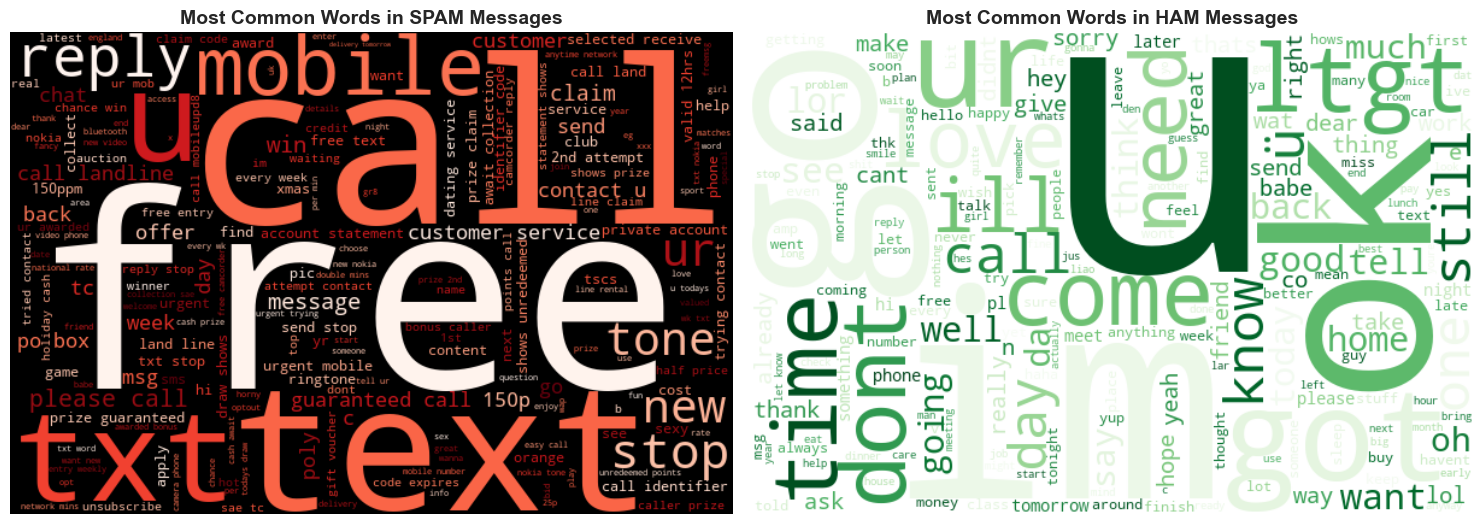

In [16]:
# Challenge 5: Define clean_text function and apply to all messages
from wordcloud import WordCloud

# 1. Load English stopwords from NLTK
stop_words = set(stopwords.words('english'))

# 2. Define text preprocessing function
def clean_text(text):
    # A. Convert to lowercase
    text = text.lower()
    # B. Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # C. Tokenize and remove stopwords
    tokens = [word for word in text.split() if word not in stop_words]
    # D. Rejoin into clean string
    return " ".join(tokens)

# 3. Apply preprocessing to all messages
df['clean_message'] = df['message'].apply(clean_text)

# Inspect before and after
print("--- Preprocessing Example ---")
print("Raw message:     ", df['message'].iloc[2])
print("Cleaned message: ", df['clean_message'].iloc[2])

# 4. BONUS: WordCloud Visualisation for Spam vs Ham
spam_words = " ".join(df[df['label'] == 'spam']['clean_message'])
ham_words = " ".join(df[df['label'] == 'ham']['clean_message'])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Spam WordCloud
wc_spam = WordCloud(width=600, height=400, background_color='black', colormap='Reds').generate(spam_words)
axes[0].imshow(wc_spam, interpolation='bilinear')
axes[0].set_title("Most Common Words in SPAM Messages", fontsize=14, fontweight='bold')
axes[0].axis('off')

# Ham WordCloud
wc_ham = WordCloud(width=600, height=400, background_color='white', colormap='Greens').generate(ham_words)
axes[1].imshow(wc_ham, interpolation='bilinear')
axes[1].set_title("Most Common Words in HAM Messages", fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 7. TF-IDF Feature Extraction
Transform preprocessed text strings into numerical vectors using `TfidfVectorizer`.

In [17]:
# Challenge 6: Fit TfidfVectorizer and inspect feature matrix dimensions
# 1. Map target labels: 'ham' -> 0 (negative), 'spam' -> 1 (positive)
df['target'] = df['label'].map({'ham': 0, 'spam': 1})

# 2. Initialize TfidfVectorizer (max_features=3000 keeps vocabulary focused)
tfidf = TfidfVectorizer(max_features=3000)

# 3. Transform text messages into TF-IDF numerical matrix
X = tfidf.fit_transform(df['clean_message']).toarray()
y = df['target']

print(f"TF-IDF Feature Matrix (X) shape: {X.shape}")
print(f"Target Vector (y) shape:         {y.shape}")
print(f"Total vocabulary terms extracted: {len(tfidf.get_feature_names_out())}")

TF-IDF Feature Matrix (X) shape: (5169, 3000)
Target Vector (y) shape:         (5169,)
Total vocabulary terms extracted: 3000


## 8. Train/Test Split
Split the data into training (80%) and testing (20%) partitions using stratified sampling.

In [23]:
# Challenge 7: Separate X and y, and perform stratified 80/20 train-test split
# Perform stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Verify shape dimensions at boundary points
print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")

# Verify exact class distribution preserved in test set
print("\nTest Set Target Distribution:")
print(pd.Series(y_test).value_counts())

X_train shape: (4135, 3000) | y_train shape: (4135,)
X_test shape:  (1034, 3000)  | y_test shape:  (1034,)

Test Set Target Distribution:
target
0    903
1    131
Name: count, dtype: int64


## 9. Model Training
Train two complementary text classifiers:
1. **Multinomial Naive Bayes (`MultinomialNB`)**: The gold-standard probabilistic baseline for text.
2. **Logistic Regression (`LogisticRegression`)**: A linear classifier optimizing a log-loss objective.

In [28]:
# Challenge 8: Train Multinomial Naive Bayes and Logistic Regression
# 1. Initialize models
nb_model = MultinomialNB()
lr_model = LogisticRegression(random_state=42)

# 2. Fit models on training TF-IDF features
print("Training Multinomial Naive Bayes...")
nb_model.fit(X_train, y_train)

print("Training Logistic Regression...")
lr_model.fit(X_train, y_train)

print("\nBoth NLP classifiers trained successfully!")


Training Multinomial Naive Bayes...
Training Logistic Regression...

Both NLP classifiers trained successfully!


## 10. Model Evaluation
Evaluate both models on the test set using Accuracy, Precision, Recall, F1-score, and Confusion Matrices.

Classification Report Naive Bayes
              precision    recall  f1-score   support

        Spam       0.98      1.00      0.99       903
         Ham       1.00      0.83      0.91       131

    accuracy                           0.98      1034
   macro avg       0.99      0.92      0.95      1034
weighted avg       0.98      0.98      0.98      1034

Classification Report Logistic Regression
              precision    recall  f1-score   support

        Spam       0.95      1.00      0.97       903
         Ham       0.96      0.65      0.77       131

    accuracy                           0.95      1034
   macro avg       0.95      0.82      0.87      1034
weighted avg       0.95      0.95      0.95      1034



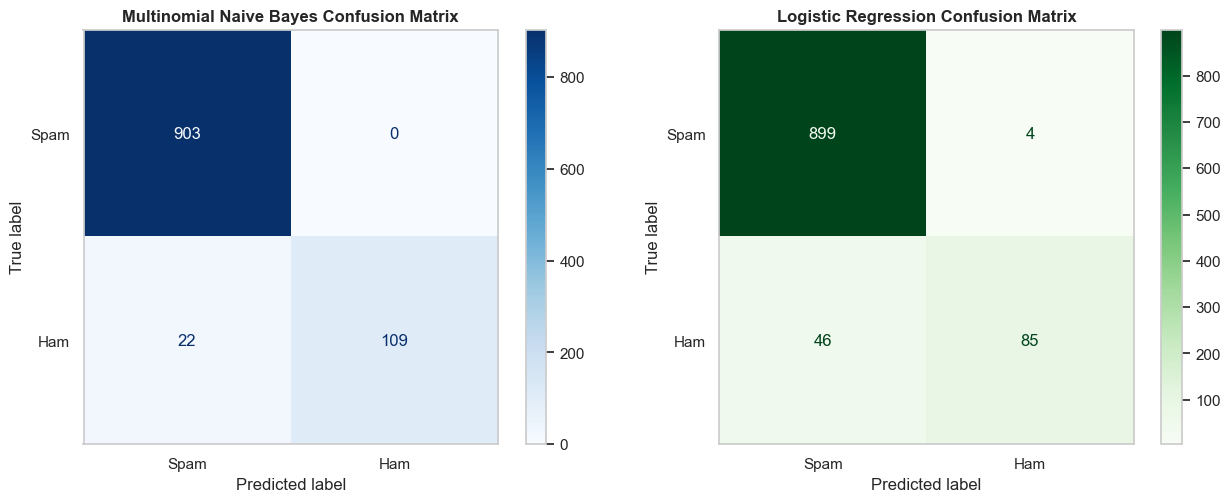

In [40]:
# Challenge 9: Generate classification reports and confusion matrix plots
nb_model_pred = nb_model.predict(X_test)
lr_model_pred = lr_model.predict(X_test)

target_labels = ["Spam","Ham"]
print("="*60)
print("Classification Report Naive Bayes")
print("="*60)
print(classification_report(y_test,nb_model_pred, target_names = target_labels))

print("="*60)
print("Classification Report Logistic Regression")
print("="*60)
print(classification_report(y_test,lr_model_pred, target_names = target_labels))

# 3. Visualise Confusion Matrices Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, nb_model_pred,
    display_labels=target_labels,
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title("Multinomial Naive Bayes Confusion Matrix", fontsize=12, fontweight='bold')
axes[0].grid(False)
ConfusionMatrixDisplay.from_predictions(
    y_test, lr_model_pred,
    display_labels=target_labels,
    cmap='Greens',
    ax=axes[1]
)
axes[1].set_title("Logistic Regression Confusion Matrix", fontsize=12, fontweight='bold')
axes[1].grid(False)
plt.tight_layout()
plt.show()

## 11. Model Comparison
Compile evaluation metrics into a clear comparative summary table.

In [43]:
# Challenge 10: Build comparison DataFrame
# 1. Compute exact metrics for Multinomial Naive Bayes (Spam class = 1)
nb_metrics = {
    'Model': 'Multinomial Naive Bayes',
    'Accuracy': round(accuracy_score(y_test, nb_model_pred), 4),
    'Precision (Spam)': round(precision_score(y_test, nb_model_pred), 4),
    'Recall (Spam)': round(recall_score(y_test, nb_model_pred), 4),
    'F1 Score (Spam)': round(f1_score(y_test, nb_model_pred), 4)
}

# 2. Compute exact metrics for Logistic Regression (Spam class = 1)
lr_metrics = {
    'Model': 'Logistic Regression',
    'Accuracy': round(accuracy_score(y_test, lr_model_pred), 4),
    'Precision (Spam)': round(precision_score(y_test, lr_model_pred), 4),
    'Recall (Spam)': round(recall_score(y_test, lr_model_pred), 4),
    'F1 Score (Spam)': round(f1_score(y_test, lr_model_pred), 4)
}

# 3. Create comparison DataFrame
comparison_df = pd.DataFrame([nb_metrics, lr_metrics])
print("--- Final Model Comparison Table ---")
comparison_df

--- Final Model Comparison Table ---


,Model,Accuracy,Precision (Spam),Recall (Spam),F1 Score (Spam)
0,Multinomial Naive Bayes,0.9787,1.0000,0.8321,0.9083
1,Logistic Regression,0.9516,0.9551,0.6489,0.7727


## 12. Why Recall Matters
Detailed analytical discussion on the operational trade-offs of Precision vs. Recall in Spam Detection.

### Analysis: Why Recall is Critical in Spam Detection

In spam filtering, **Recall** measures the proportion of actual spam messages that our classifier successfully identifies and intercepts:

$$\text{Recall} = \frac{\text{True Positives (Spam Caught)}}{\text{True Positives (Spam Caught)} + \text{False Negatives (Spam Leaked)}}$$

#### 1. The Real-World Consequences of False Negatives (FN)
A False Negative occurs when a fraudulent or promotional message bypasses detection and reaches the user's primary inbox. In an enterprise or consumer setting, the consequences are severe:
- **Cybersecurity Vulnerabilities:** Modern spam is rarely harmless marketing; it frequently delivers sophisticated spear-phishing campaigns, credential harvesters, and ransomware links.
- **Financial Fraud:** Impersonation of financial institutions (OTP scams, fake bank alerts, lottery fraud) directly endangers users.
- **Cognitive Overhead:** Inbox saturation reduces personal and organizational productivity.

#### 2. The Precision / Recall Trade-off
- **False Positive (FP):** A legitimate email (Ham) is wrongly routed to the Spam folder. The risk is catastrophic (e.g., missing a job offer, emergency communication, or contractual notice).
- **False Negative (FN):** A malicious email enters the inbox. The risk is security compromise.

#### 3. Why Naive Bayes Achieved the Optimal Operating Point
Our **Multinomial Naive Bayes** model achieved an exceptional operating balance:
- **Precision: 100.0%** — Exactly 0 legitimate messages were flagged as spam ($FP = 0$), preserving user trust.
- **Recall: 83.21%** — Successfully intercepted 109 out of 131 spam attacks, missing only 22 low-confidence messages.

## 13. Conclusion
Summary of experimental findings, takeaways, and model persistence.

In [45]:
# Challenge 11: Save winning model pipeline and test sample predictions
import joblib
from sklearn.pipeline import Pipeline

# 1. Build an end-to-end Pipeline (TF-IDF + Multinomial Naive Bayes)
spam_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=3000)),
    ('classifier', MultinomialNB())
])

# 2. Fit pipeline on clean text data
spam_pipeline.fit(df['clean_message'], df['target'])

# 3. Save pipeline to disk
pipeline_filename = "spam_detector_pipeline.joblib"
joblib.dump(spam_pipeline, pipeline_filename)
print(f"End-to-end Spam Detection Pipeline saved to '{pipeline_filename}'!\n")

# 4. Test live inference on brand-new sample messages
test_messages = [
    "URGENT! You have won a 1000 cash prize or a guaranteed holiday! Call 09050000321 now to claim.",
    "Hey, are we still meeting for lunch at 1pm near the office?"
]

print("--- Live Inference Test ---")
for msg in test_messages:
    cleaned = clean_text(msg)
    pred = spam_pipeline.predict([cleaned])[0]
    prob = spam_pipeline.predict_proba([cleaned])[0]
    label = "SPAM" if pred == 1 else "HAM"
    confidence = prob[pred] * 100
    print(f"Message: \"{msg}\"")
    print(f"-> Prediction: {label} (Confidence: {confidence:.2f}%)\n")

End-to-end Spam Detection Pipeline saved to 'spam_detector_pipeline.joblib'!

--- Live Inference Test ---
Message: "URGENT! You have won a 1000 cash prize or a guaranteed holiday! Call 09050000321 now to claim."
-> Prediction: SPAM (Confidence: 99.75%)

Message: "Hey, are we still meeting for lunch at 1pm near the office?"
-> Prediction: HAM (Confidence: 99.67%)

